In [205]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

In [206]:
stu = pd.read_csv(f"D:\\SevenMentor\\ML\\workspace\\model_trian\\Performance_of_Stuednts.csv")

In [207]:
stu

,gender,race/group,parental education level,lunch,test prep course,math score,science score,english score
0,Female,Group 10,bachelor's degree,standard,none,66,72,74
1,Female,Group 20,some college,standard,completed,69,90,88
2,Female,Group 10,master's degree,standard,none,90,88,93
3,Male,Group 9,associate's degree,free/reduced,none,47,57,44
4,Male,Group 20,some college,standard,none,76,44,75
...,...,...,...,...,...,...,...,...
995,Female,Group 11,master's degree,standard,completed,88,99,95
996,Male,Group 20,high school,free/reduced,none,62,55,55
997,Female,Group 20,high school,free/reduced,completed,59,71,65
998,Female,Group 8,some college,standard,completed,68,78,77


# perform EDA on Student data set

stu.head()

In [208]:
stu.head()

,gender,race/group,parental education level,lunch,test prep course,math score,science score,english score
0,Female,Group 10,bachelor's degree,standard,none,66,72,74
1,Female,Group 20,some college,standard,completed,69,90,88
2,Female,Group 10,master's degree,standard,none,90,88,93
3,Male,Group 9,associate's degree,free/reduced,none,47,57,44
4,Male,Group 20,some college,standard,none,76,44,75


In [209]:
stu.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   gender                    1000 non-null   str  
 1   race/group                1000 non-null   str  
 2   parental education level  1000 non-null   str  
 3   lunch                     1000 non-null   str  
 4   test prep course          1000 non-null   str  
 5   math score                1000 non-null   int64
 6   science score             1000 non-null   int64
 7   english score             1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [210]:
stu.shape

(1000, 8)

In [211]:
stu.isnull().sum()

gender                      0
race/group                  0
parental education level    0
lunch                       0
test prep course            0
math score                  0
science score               0
english score               0
dtype: int64

In [212]:
stu.duplicated().sum()


np.int64(0)

In [213]:
stu["overall_score"] = stu[["math score","science score","english score"]].mean(axis=1)
overall_score = stu["overall_score"].mean()
print(f"Overall Score: {overall_score}")

Overall Score: 67.754


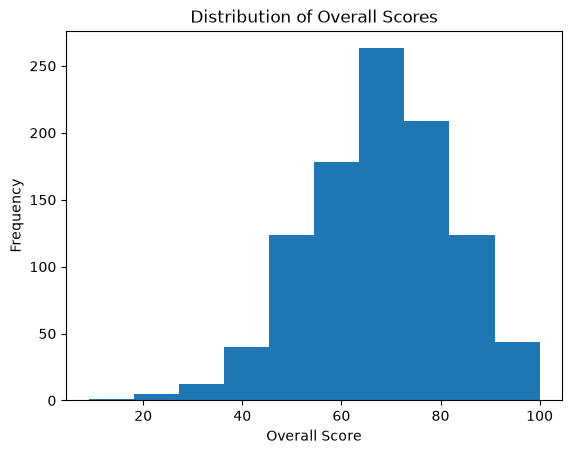

In [214]:
plt.hist(stu["overall_score"])
plt.title("Distribution of Overall Scores")
plt.xlabel("Overall Score")
plt.ylabel("Frequency")
plt.show()

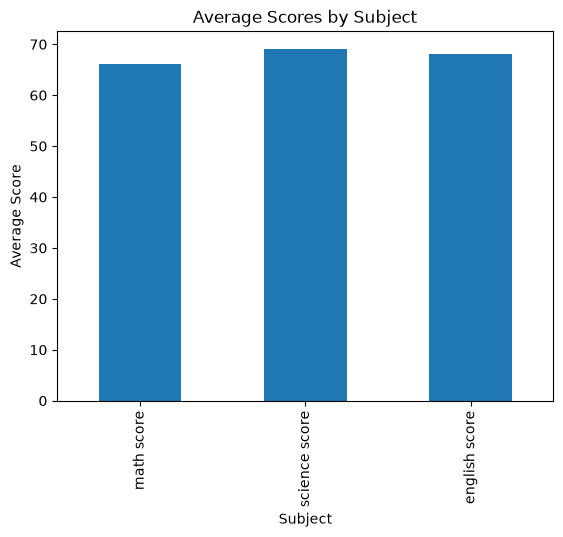

In [215]:
stu[["math score", "science score", "english score"]].mean().plot(kind="bar")
plt.title("Average Scores by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.show()

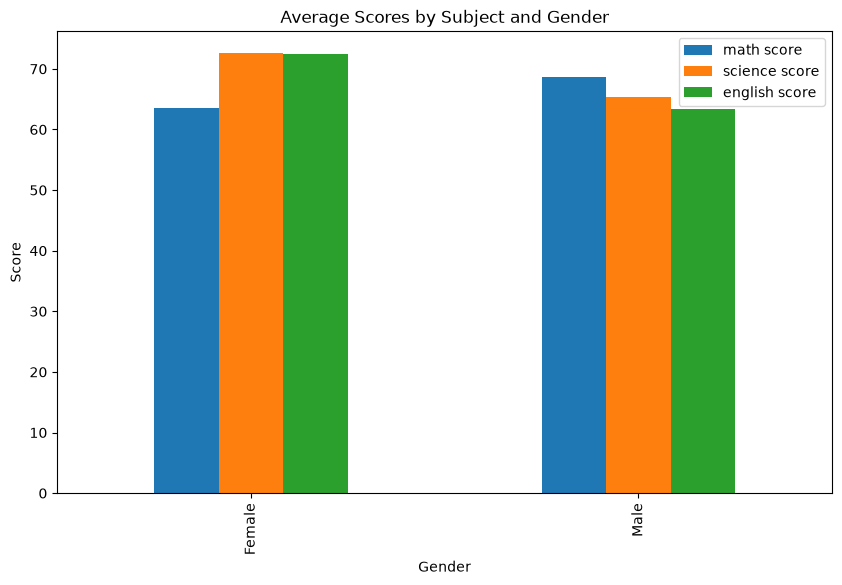

In [216]:

stu.groupby("gender")[["math score", "science score", "english score"]].mean().plot(kind="bar", figsize=(10,6)) 
plt.title("Average Scores by Subject and Gender")
plt.xlabel("Gender")
plt.ylabel("Score")
plt.show()

# Perform FE on data

In [217]:
# drop columen

stu = stu.drop(stu[["lunch","race/group", "parental education level", "overall_score"]], axis=1)

In [218]:
stu

,gender,test prep course,math score,science score,english score
0,Female,none,66,72,74
1,Female,completed,69,90,88
2,Female,none,90,88,93
3,Male,none,47,57,44
4,Male,none,76,44,75
...,...,...,...,...,...
995,Female,completed,88,99,95
996,Male,none,62,55,55
997,Female,completed,59,71,65
998,Female,completed,68,78,77


In [219]:
stu.nunique()

gender               2
test prep course     2
math score          81
science score       72
english score       77
dtype: int64

In [220]:
le_1 = LabelEncoder()
le_2 = LabelEncoder()
me_1 = MinMaxScaler()
me_2 = MinMaxScaler()
me_3 = MinMaxScaler()

In [222]:
stu["gender_en"] = le_1.fit_transform(stu["gender"])
stu["test_prep_course_en"] = le_2.fit_transform(stu["test prep course"])
stu["math_score_en"] = me_1.fit_transform(stu[["math score"]])
stu["science_score_en"] = me_2.fit_transform(stu[["science score"]])
stu["english_score_en"] = me_3.fit_transform(stu[["english score"]])
stu.drop(stu[["test prep course", "gender", "math score", "science score", "english score"]], axis=1, inplace=True)

In [224]:
x = stu.drop("math_score_en", axis=True)
y = stu["math_score_en"]

In [225]:
x

,gender_en,test_prep_course_en,science_score_en,english_score_en
0,0,1,0.662651,0.711111
1,0,0,0.879518,0.866667
2,0,1,0.855422,0.922222
3,1,1,0.481928,0.377778
4,1,1,0.325301,0.722222
...,...,...,...,...
995,0,0,0.987952,0.944444
996,1,1,0.457831,0.500000
997,0,0,0.650602,0.611111
998,0,0,0.734940,0.744444


In [226]:
y

0      0.66
1      0.69
2      0.90
3      0.47
4      0.76
       ... 
995    0.88
996    0.62
997    0.59
998    0.68
999    0.77
Name: math_score_en, Length: 1000, dtype: float64

In [227]:
# split data
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, shuffle=True)

In [228]:
# train model
# from sklearn.linear_model import mse

model = LinearRegression()

model.fit(X_train, y_train)
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

y_pred = model.predict(X_test)

mse = np.sqrt(np.mean((y_test - y_pred)**2))
print(f"Mean Squared Error: {mse}")


Intercept: 0.010758234182571935
Coefficients: [0.13547067 0.03516957 0.21899613 0.65975515]
Mean Squared Error: 0.055282077560855854


In [230]:
y_pred = model.predict([[0,1,0.662651,0.711111]])

d:\SevenMentor\ML\workspace\.ml_work\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [232]:
math_score_pred = me_1.inverse_transform(y_pred.reshape(-1, 1))

In [233]:
math_score_pred

array([[66.02049572]])